# Human preference prediction: problem and data

Given a prompt and two anonymous LLM responses, predict the probabilities of A winning,
B winning, or a tie. This is preference modeling rather than ordinary topic classification.
The metric is multiclass log loss; lower is better.

[Competition](https://www.kaggle.com/competitions/llm-classification-finetuning) ·
[Evaluation](https://www.kaggle.com/competitions/llm-classification-finetuning/overview/evaluation) ·
[Experiment contract](../docs/EXPERIMENT_PLAN.md)

The competition is ongoing with a rolling leaderboard. It requires notebook submissions
with internet disabled and a maximum runtime of 9 hours. Only three example test rows
are visible locally; Kaggle substitutes the hidden test set when scoring.


In [1]:
from pathlib import Path
import json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
REPO = Path.cwd()
if REPO.name == 'notebooks': REPO = REPO.parent
sys.path.insert(0, str(REPO / 'src'))
from arena.data import ROOT, CLASSES, TEXT_COLUMNS
RESULTS = REPO / 'results/attempt_001'
ARTIFACTS = ROOT / 'runs/attempt_001'
FIGURES = ROOT / 'reports/attempt_001'
FIGURES.mkdir(parents=True, exist_ok=True)
summary = json.loads((RESULTS / 'data_summary.json').read_text())
evaluation = json.loads((RESULTS / 'metrics.json').read_text()) if (RESULTS/'metrics.json').exists() else None
comparison = pd.read_json(RESULTS / 'comparison.json').sort_values('dev_log_loss') if (RESULTS/'comparison.json').exists() else None
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.spines.top': False, 'axes.spines.right': False})


In [2]:
display(pd.Series({k: summary[k] for k in ['train_rows','visible_test_rows','unique_prompt_groups','prompt_overlap_across_splits']}))
display(pd.Series(summary['raw_sha256'], name='Original file SHA-256'))

train_rows                      57477
visible_test_rows                   3
unique_prompt_groups            51213
prompt_overlap_across_splits        0
dtype: int64

train.csv                0692154aaf20fc6649090c3f49b6b5dd1e693a765ecb5f...
sample_submission.csv    e57b163939f13472cb79f019436a3d980fa1fd6fc69db6...
test.csv                 4d6a47208951532a0b6bf862a75531806270f4782afc34...
Name: Original file SHA-256, dtype: str

## Targets and conversation lengths

CSV text fields are JSON lists of turns. We parse them with `json.loads`, retain turn
boundaries, and preserve empty responses. Model identity columns occur only in training
and cannot be used for test prediction. IDs are excluded as features.


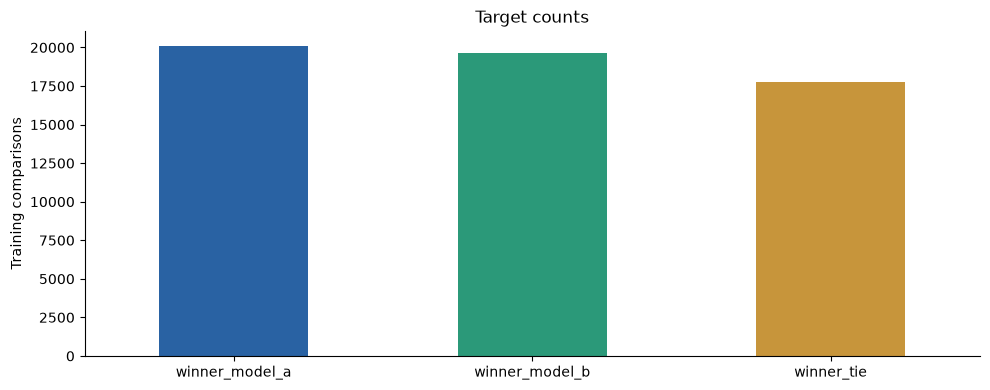

,prompt,response_a,response_b
count,57477.0,57477.0,57477.0
mean,354.6,1332.6,1339.4
std,1026.4,1466.8,1488.6
min,3.0,0.0,0.0
50%,92.0,1037.0,1045.0
90%,764.0,2707.0,2700.0
95%,1427.0,3589.2,3588.0
99%,4705.4,6807.0,6764.7
max,32869.0,53605.0,52681.0


In [3]:
counts = pd.Series(summary['counts'])
ax = counts.plot.bar(color=['#2962A3','#2B9979','#C7953B'], rot=0)
ax.set(ylabel='Training comparisons', title='Target counts'); plt.tight_layout(); plt.savefig(FIGURES/'target_counts.svg'); plt.show()
display(pd.DataFrame(summary['text_lengths']).round(1))

## Leakage control

Normalize prompt whitespace and case, then group identical prompts. Split into 8 training
folds, 1 development fold, and 1 final holdout fold using stratified group splitting.
All representations use these same partitions. Vocabulary, IDF, SVD, scalers, and GRU
weights are learned on training rows. Development chooses settings and stopping points.
Final holdout labels are read for evaluation only after the ensemble is frozen.


In [4]:
display(pd.DataFrame(summary['class_proportions_by_split'], index=CLASSES).T)
print(summary['split'])
assert summary['prompt_overlap_across_splits'] == 0

,winner_model_a,winner_model_b,winner_tie
train,16050,15721,14209
dev,2007,1965,1776
holdout,2007,1966,1776


StratifiedGroupKFold(10): folds 2..9 train; 1 dev; 0 holdout


## Reproduce the audit

Install the locked environment with `uv sync`, then run
`uv run python scripts/download_data.py` and
`uv run python scripts/run_experiments.py prepare`.
Heavy files and split manifests remain under `~/database/llm_classification_finetuning`.
This notebook uses the committed aggregate audit so the results remain readable without
copying raw competition text into GitHub.
